In [2]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.metrics import mean_squared_error, r2_score

In [3]:
# Load California Housing dataset
data = fetch_california_housing()
X, y = data.data, data.target        # X = 8 features, y = house price

# Split into 80% train and 20% test
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Scale features (mean = 0, std = 1)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Add a column of 1s for the intercept (bias) term
Xb_train = np.c_[np.ones(X_train.shape[0]), X_train]
Xb_test = np.c_[np.ones(X_test.shape[0]), X_test]

print("Train shape:", Xb_train.shape)
print("Test shape:", Xb_test.shape)

Train shape: (16512, 9)
Test shape: (4128, 9)


In [4]:
# Normal Equation: theta = (X^T X)^-1 X^T y
theta_ne = np.linalg.pinv(Xb_train.T @ Xb_train) @ Xb_train.T @ y_train

y_pred_ne = Xb_test @ theta_ne

print("Normal Equation -> MSE:", mean_squared_error(y_test, y_pred_ne))
print("Normal Equation -> R2 :", r2_score(y_test, y_pred_ne))

Normal Equation -> MSE: 0.5558915986952424
Normal Equation -> R2 : 0.5757877060324523


Gradient Descent -> MSE: 0.5559984462926857
Gradient Descent -> R2 : 0.5757061684367721


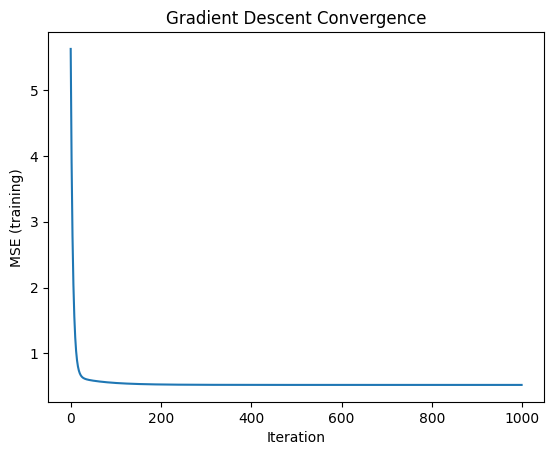

In [5]:
lr = 0.1            # learning rate
epochs = 1000       # number of iterations
m = Xb_train.shape[0]

theta_gd = np.zeros(Xb_train.shape[1])   # start with all weights = 0
losses = []

for i in range(epochs):
    y_hat = Xb_train @ theta_gd                  # 1. predict
    error = y_hat - y_train                      # 2. find error
    gradient = (1/m) * Xb_train.T @ error        # 3. compute gradient
    theta_gd = theta_gd - lr * gradient          # 4. update weights
    losses.append(np.mean(error**2))             # store MSE for plotting

y_pred_gd = Xb_test @ theta_gd

print("Gradient Descent -> MSE:", mean_squared_error(y_test, y_pred_gd))
print("Gradient Descent -> R2 :", r2_score(y_test, y_pred_gd))

# Plot the loss curve
plt.plot(losses)
plt.xlabel("Iteration")
plt.ylabel("MSE (training)")
plt.title("Gradient Descent Convergence")
plt.show()

In [6]:
# Models (use the scaled data WITHOUT the extra column of 1s; sklearn adds the intercept itself)
models = {
    "Linear Regression": LinearRegression(),
    "Ridge (alpha=1)":   Ridge(alpha=1.0),
    "Lasso (alpha=0.01)": Lasso(alpha=0.01),
}

results = {}
for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)
    results[name] = pred
    print(f"{name:20s} MSE = {mean_squared_error(y_test, pred):.4f} | R2 = {r2_score(y_test, pred):.4f}")

Linear Regression    MSE = 0.5559 | R2 = 0.5758
Ridge (alpha=1)      MSE = 0.5559 | R2 = 0.5758
Lasso (alpha=0.01)   MSE = 0.5483 | R2 = 0.5816


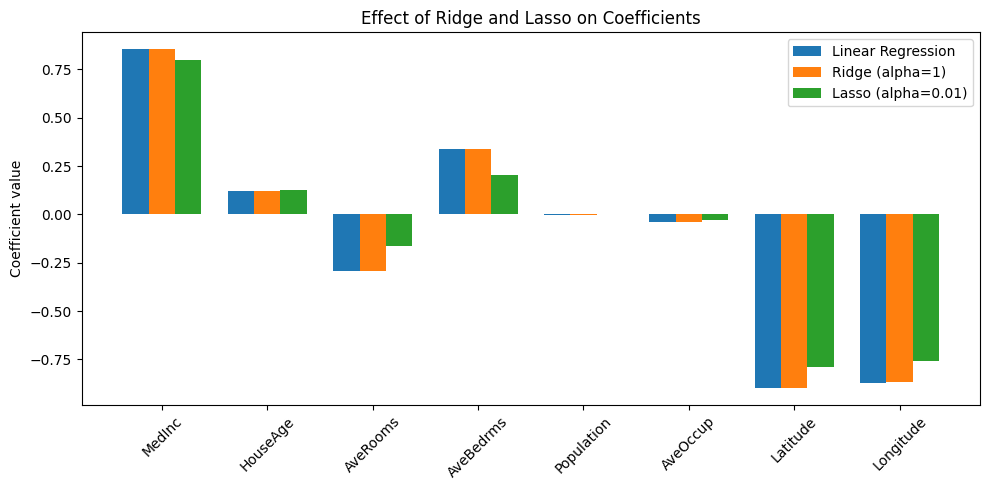

In [7]:
features = data.feature_names
x_pos = np.arange(len(features))
width = 0.25

plt.figure(figsize=(10, 5))
for i, (name, model) in enumerate(models.items()):
    plt.bar(x_pos + i*width, model.coef_, width, label=name)

plt.xticks(x_pos + width, features, rotation=45)
plt.ylabel("Coefficient value")
plt.title("Effect of Ridge and Lasso on Coefficients")
plt.legend()
plt.tight_layout()
plt.show()

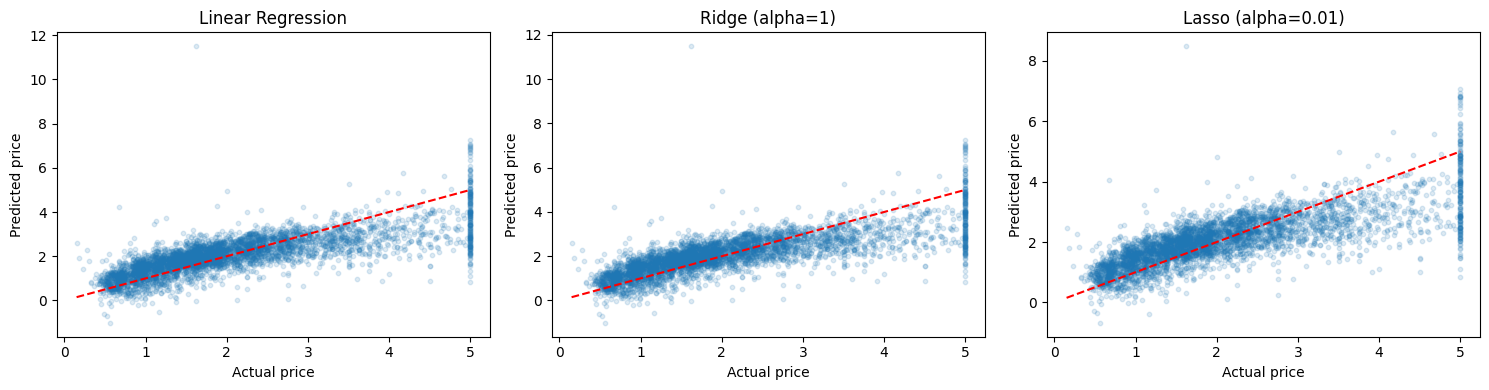

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (name, pred) in zip(axes, results.items()):
    ax.scatter(y_test, pred, alpha=0.15, s=10)
    ax.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], 'r--')  # perfect line
    ax.set_xlabel("Actual price")
    ax.set_ylabel("Predicted price")
    ax.set_title(name)

plt.tight_layout()
plt.show()